# Limitation 6 — Errors of the model, and the noise

**The atoms take four things as known: each window's zero point, the width of the line-spread function, the noise σ of each sample, and the list of sources in the scene. Each is an input, not a fit, and an error in any one of them goes straight into the answer. The joint fit takes a fifth by default, the primary's position, and can fit it instead. The noise itself, with no error in its description, has its own effect on the two pictures.**

Every limitation notebook has the same four parts. **The premise** states
what the atoms assume and shows the case that breaks it. Then **one section
per atom**, always in the same order, the two images of the windows, the map
of detections, the joint fit, each answering three questions: what does this
atom assume here, what does it return in this case, and does it warn you.
**The summary table** closes with the same columns every time: atom, effect,
alarm, remedy.

The case of this page: the control pair, 200 mas at position angle 110°, on 80 windows at S/N 100; one input put in error at a time, zero points off by 10 mas rms, the LSF 5 and 10 % wider or narrower than the model, the noise σ told as half or double, a third star left out; and the same scene at S/N 10. For the joint fit alone, the reference position put 1 to 10 mas off the primary, fitted with the primary pinned and free.

| block | task | calls | paper |
|---|---|---|---|
| 1 | the premise: one window and the residual each input in error leaves | `ins.render_window`, `joint.scene_positions_al`, `ins.Instrument.gaussian` | Sect. 2.1, Eqs. 3–4; Sect. 6.2 |
| 2 | the two images with the zero points ignored, and with noise | `radon.filtered_backprojection`, `radon.faststack` | App. C.2, Eq. C.3 |
| 3 | the map with the zero points added back and ignored | `bp.map_peak`, `bp.peak_consistency` | Sect. 3.3, Eq. 13 |
| 4 | the joint fit with each input in error; the reference position off the primary, pinned and free | `joint.fit_joint` | Sect. 4.3, Eq. 18; Sect. 6.2; Sect. 6.3 |

Every scanlib call carries the name of its module (`joint.fit_joint`); the first code cell lists the modules.

**The series.** The three images and the fit are in [`../00_three_images_and_fit.ipynb`](../00_three_images_and_fit.ipynb). The limitations: [1 — the finite window](01_finite_window.ipynb), [2 — the scan law](02_scan_law.ipynb), [3 — one line, two lines, three](03_few_lines.ipynb), [4 — a scene that moves](04_motion.ipynb), [5 — the blend](05_blend.ipynb), this page.

**Symbols and units** are defined once for the package and every notebook in [`docs/conventions.md`](../../../docs/conventions.md). This page uses ψ, η, η₀, the LSF width, σ and S/N, σ_η and the detections, the two images, the map and its width, θ, the Fisher σ, the pull, and χ²/dof.

In [1]:
# the imports: numpy, matplotlib, and the scanlib modules; every scanlib call below carries its module's name
import numpy as np
import matplotlib.pyplot as plt

from scanlib import instrument as ins      # the instrument: sampling, LSF, the along-scan projection (Eq. 9)
from scanlib import simulation as sim      # synthetic scenes and their windows
from scanlib import backprojection as bp   # the triangulation map and its peak
from scanlib import radon                  # the inverse Radon transform and faststack
from scanlib import joint                  # the joint fit of all windows, and its helpers

In [2]:
# the paper's figure style: font 10, ticks 9 and inward, thin axes; grays first, one accent
plt.rcParams.update({"font.size": 10.0, "axes.linewidth": 0.5, "xtick.labelsize": 9.0, "ytick.labelsize": 9.0,
                     "xtick.direction": "in", "ytick.direction": "in", "legend.frameon": False, "legend.fontsize": 7.5})
ACCENT = "tomato"                                          # the one accent
# the markers: each name below in capitals with dict(...) is a table of the keywords that ax.scatter takes for
# one kind of point
SEED = dict(marker="o", s=60, facecolor="none", edgecolor=ACCENT, lw=1.1, zorder=6)  # a starting point (the map's peak)
# the labels of the two sky axes
EAST = r"$\Delta\alpha^{*}$  [mas]   (East $\leftarrow$)"
NORTH = r"$\Delta\delta$  [mas]"


def letter(ax, label, text=""):
    """Write a panel's letter, bold, inside the panel's top-left corner, and a few words after it.

    Inputs
        ax      the panel (a matplotlib Axes)
        label   the panel's letter, for example "a"
        text    the words after the letter (default: none)
    Returns nothing: the letter and the words are drawn on ax, on a white box that dims what is under them."""
    white_box = dict(fc="white", ec="none", pad=1.0, alpha=0.8)
    ax.text(0.04, 0.96, rf"$\bf{{({label})}}$ " + text, transform=ax.transAxes, va="top", ha="left", fontsize=9,
            bbox=white_box)

In [3]:
# the toy instrument, the noise, the pair's position angle and fluxes, the two sets of scan directions, and the
# sky grid of every image
FWHM = 100.0                                 # the LSF's full width at half maximum [mas]
# The instrument, defined once: 18 samples 59 mas apart, a Gaussian LSF of
# that FWHM, and the trial positions of the per-window reduction.
inst = ins.Instrument.gaussian(fwhm_mas=FWHM, pitch_mas=59.0, n_samples=18)
grid = inst.sample_grid_mas                  # sample centers along the scan [mas]
pitch = grid[1] - grid[0]                    # the distance between two neighboring samples: 59 mas
sigma_lsf = FWHM / (2.0 * np.sqrt(2.0 * np.log(2.0)))   # LSF sigma [mas], for the formulas
sigma_noise = 10.0                           # the noise sigma of one sample; the primary's total flux is 100 sigma
pa = np.deg2rad(110.0)                       # the pair's position angle [rad], counter-clockwise from north
flux = np.array([1000.0, 200.0])             # the fluxes of the primary and of the companion, in the windows' units
EVEN = np.linspace(0.0, np.pi, 80, endpoint=False) + 0.01     # 80 even directions [rad]
# ref: the reference cases of the package's tests, a table from a case's name to its array; two of its inputs
# are used here
ref = np.load("../../../tests/reference/reference_cases.npz")
GAIA = ref["static_pair/inputs/psi"]                           # the Gaia forecast's 40 scan angles [rad]
GAIA_TAU = ref["moving_pair/inputs/tau"]                       # and epochs [yr]
half = 400.0                                 # the sky grid of every image: half the side of the square [mas]
step = 4.0                                   # and the size of one pixel [mas]
# degrees of freedom of a static two-source fit on 80 windows: 80 x 18 samples, minus the companion's two
# coordinates and the two fluxes
DOF = EVEN.size * grid.size - 4

In [4]:
# helper: the companion's sky offset at a separation on the pair axis
def pair(rho):
    """The companion's sky offset at a separation on the pair axis (the direction of position angle pa).

    Inputs
        rho   the companion's separation from the primary [mas]
    Returns
        the companion's (dra*, ddec) [mas] from the primary, an array of two numbers"""
    pair_axis = np.array([np.sin(pa), np.cos(pa)])            # the unit vector of the pair axis, (dra*, ddec)
    return rho * pair_axis

In [5]:
# helper: the windows of a scene, noise-free or noisy (ins.render_window, sim.simulate_window)
def windows_of(theta, psi, flux=flux, tau=None, rng=None, present=None, eta0=None, inst=inst):
    """The windows of a scene, one per scan: noise-free (a formula), or with one draw of noise each.

    Inputs
        theta     the companions' parameters, one flat array: (dra*, ddec) [mas] per companion for a static scene,
                  (dra*, ddec [mas], mu_alpha*, mu_delta [mas/yr]) per companion for a moving one. The primary is
                  at the origin and has no entry
        psi       the scan angle of each of the J windows [rad]
        flux      the flux of each of the K sources, in the windows' units, the primary first
        tau       the epoch of each window [yr] for a moving scene (None: a static scene)
        rng       the random generator of the noise, of sigma_noise per sample (None: noise-free windows)
        present   J rows of K booleans: which source is in which window (None: every source in every window)
        eta0      the zero point of each window [mas] (None: every zero point is 0)
        inst      the instrument that renders the windows (default: the page's instrument)
    Returns
        the windows, an array of J rows of N samples, flux per sample"""
    # step 1, the along-scan position of every source in every window [mas]: one row per window, one column per
    # source, the primary first. Each window's zero point is subtracted from its row; [:, None] turns the J zero
    # points into a column, so that row j gets eta0[j]
    eta = joint.scene_positions_al(theta, psi, tau)
    if eta0 is not None:
        eta = eta - np.asarray(eta0)[:, None]

    # step 2, one window per scan; j counts the windows
    windows = []
    for j, eta_j in enumerate(eta):
        # the fluxes in window j: present[j] holds one True or False per source, and a source that is not in
        # the window gets flux 0
        if present is None:
            flux_j = flux
        else:
            flux_j = flux * present[j]
        # the samples of window j: the noise-free model, or the model plus one draw of noise from rng
        if rng is None:
            window = ins.render_window(eta_j, flux_j, inst)
        else:
            window = sim.simulate_window(eta_j, flux_j, inst, rng, sigma_noise)
        windows.append(window)
    return np.array(windows)

In [6]:
# helper, a stand-in for the per-window reduction: the Fisher error of each companion's position in one window
def sigma_eta(eta, flux=flux, sigma_noise=sigma_noise):
    """The Fisher error of each companion's along-scan position in one window, with every flux free. It is a
    formula, not a fit: it stands in for the error that the per-window reduction would report.

    Inputs
        eta           the along-scan position of each of the K sources in the window [mas], the primary first
        flux          the flux of each of the K sources, in the windows' units, the primary first
        sigma_noise   the noise sigma of one sample, in the windows' units
    Returns
        the 1-sigma error of each companion's position [mas], K - 1 numbers (the primary's position is not a
        parameter); every one is infinite where the Fisher matrix is singular"""
    # step 1, the model of the window. columns[:, k] is the window of source k alone at flux 1, one number per
    # sample; derivatives[:, k] is the derivative of that column with respect to the position of source k [1/mas]
    columns = inst.design_columns(eta)
    derivatives = inst.design_jacobian(eta)

    # step 2, the derivative of the window with respect to every parameter, one column each: first the
    # companions' positions ([:, 1:] omits the primary's column and flux[1:] the primary's flux), then the K fluxes
    jacobian = np.column_stack([derivatives[:, 1:] * flux[1:], columns])

    # step 3, the Fisher matrix for Gaussian noise of known sigma. Where its condition number is above 1e12 it
    # cannot be inverted safely: the companions' positions are then not measured in this window
    fisher = jacobian.T @ jacobian / sigma_noise ** 2
    n_companions = eta.size - 1
    if np.linalg.cond(fisher) > 1e12:
        return np.full(n_companions, np.inf)

    # step 4, the errors: the square roots of the diagonal of the inverse. [:n_companions] keeps the positions'
    # entries and omits the fluxes'
    covariance = np.linalg.inv(fisher)
    return np.sqrt(np.diag(covariance)[:n_companions])

In [7]:
# helper, the stand-in's detections: the truth plus one draw of that error, where the error is below 30 mas
def detections(theta, psi, flux=flux, tau=None, sigma_max=30.0, rng=None, present=None):
    """The teaching detections of a scene, a stand-in for the per-window reduction: no window is simulated and no
    window is fitted. A detection is a companion's true along-scan position in a window plus one Gaussian draw of
    its Fisher error there (sigma_eta, at the page's noise sigma_noise).

    Inputs
        theta       the companions' parameters, one flat array, as in windows_of
        psi         the scan angle of each of the J windows [rad]
        flux        the flux of each of the K sources, in the windows' units, the primary first
        tau         the epoch of each window [yr] for a moving scene (None: a static scene)
        sigma_max   a companion gives a detection in a window only where its Fisher error is finite and at most
                    this [mas]
        rng         the random generator of the draws (None: a new generator of seed 8 at every call)
        present     J rows of K booleans: which source is in which window (None: every source in every window);
                    a companion gives no detection in a window that it is not in
    Returns three arrays, one entry per detection
        psi     the scan angle of the detection's window [rad]
        eta     the detected along-scan position [mas]: the truth plus the draw
        sigma   the 1-sigma error of that position [mas]"""
    # step 1, the generator of the detections' errors. The default is a new generator of seed 8 at every call,
    # so two calls for the same scene give the same draws (why 8: not stated)
    if rng is None:
        rng_detections = np.random.default_rng(8)
    else:
        rng_detections = rng

    # step 2, the true along-scan position of every source in every window [mas]: row j is window j, column 0
    # the primary
    eta_true = joint.scene_positions_al(theta, psi, tau)

    # step 3, one detection per window and companion that passes the two tests. j counts the windows; c counts
    # the sources of a window from 1, because source 0 is the primary and gives no detection
    detected_psi = []
    detected_eta = []
    detected_sigma = []
    for j, psi_j in enumerate(psi):
        eta_j = eta_true[j]
        sigma_j = sigma_eta(eta_j, flux)                       # the Fisher error of each companion in window j
        for c in range(1, eta_j.size):
            sigma = sigma_j[c - 1]                             # sigma_j has no entry for the primary
            if present is not None and not present[j, c]:
                continue
            if np.isfinite(sigma) and sigma <= sigma_max:
                error_draw = rng_detections.normal(0.0, sigma)
                detected_psi.append(psi_j)
                detected_eta.append(eta_j[c] + error_draw)
                detected_sigma.append(sigma)
    return np.array(detected_psi), np.array(detected_eta), np.array(detected_sigma)

In [8]:
# helper: the points of a covariance ellipse
def ellipse(cov, center, n_sigma=1.0):
    """The outline of a covariance ellipse on the sky, as points to plot.

    Inputs
        cov       the 2 x 2 covariance of a position (dra*, ddec) [mas^2]
        center    the center of the ellipse, (dra*, ddec) [mas]
        n_sigma   the size of the ellipse, its Mahalanobis radius (1: the 1-sigma ellipse)
    Returns
        200 points around the ellipse, one row (dra*, ddec) [mas] per point; the last point repeats the first"""
    # step 1, the ellipse's axes: the eigenvalues are the variances along them [mas^2], the columns of
    # eigenvectors are their directions
    eigenvalues, eigenvectors = np.linalg.eigh(cov)

    # step 2, the unit circle at 200 angles around the full turn: row 0 holds the cosines, row 1 the sines
    angles = np.linspace(0, 2 * np.pi, 200)
    unit_circle = np.vstack([np.cos(angles), np.sin(angles)])

    # step 3, the circle stretched to the ellipse's semi-axes ([:, None] makes them a column: one factor per
    # row of the circle), turned to the axes' directions, and moved to the center. .T gives one row per point
    semi_axes = n_sigma * np.sqrt(eigenvalues)[:, None]
    stretched = semi_axes * unit_circle
    turned = eigenvectors @ stretched
    return turned.T + center

In [9]:
# helper: draw one sky image or map, east to the left, with the sources marked
def show(ax, image, axis, title, marks=None, **imshow_options):
    """Draw one sky image or map, east to the left, with the sources marked by plus signs.

    Inputs
        ax               the panel (a matplotlib Axes)
        image            the image or the map, M rows of M pixels: the rows are ddec, the columns dra*
        axis             the sky coordinate of the M rows, and of the M columns [mas]
        title            the panel's title
        marks            the sources to mark, one row (dra*, ddec) [mas] each (None: the primary at the origin and
                         the companion of this page, the global theta)
        imshow_options   keywords for ax.imshow, for example vmax, the value drawn black
    Returns
        the drawn image (matplotlib's AxesImage)"""
    # step 1, the defaults of the picture, used where the call names no other: white at 0 and black at the
    # highest value, and every pixel drawn as it is (no smoothing)
    imshow_options.setdefault("cmap", "gray_r")
    imshow_options.setdefault("vmin", 0.0)
    imshow_options.setdefault("interpolation", "nearest")

    # step 2, the picture: row 0 at the bottom (north up); axis[0] and axis[-1] are the first and the last
    # coordinate, given as the picture's left and right, and bottom and top
    extent = (axis[0], axis[-1], axis[0], axis[-1])
    drawn_image = ax.imshow(image, origin="lower", extent=extent, **imshow_options)

    # step 3, the plus signs: column 0 of the marks is dra*, column 1 is ddec
    if marks is None:
        marked_sources = np.vstack([[0.0, 0.0], theta])
    else:
        marked_sources = marks
    ax.scatter(marked_sources[:, 0], marked_sources[:, 1], marker="+", s=70, color=ACCENT, lw=1.1, zorder=6)

    # step 4, the title, the label, and the direction of the horizontal axis
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(EAST)
    ax.set_aspect("equal")
    ax.set_xlim(axis[-1], axis[0])                               # east to the left
    return drawn_image

In [10]:
# helper: one printed line that compares a fit with the truth
def report(name, fit, truth, dof):
    """Print one line that compares a joint fit with the truth.

    Inputs
        name    the words that open the line
        fit     the result of joint.fit_joint, a table from a name to a value. Four entries are read:
                fit["theta"] the fitted parameters, fit["sigma_theta"] their Fisher 1-sigma errors, fit["flux"]
                the fitted fluxes (the primary first) and fit["chi2"]
        truth   the true parameters, in the order and the units of fit["theta"]
        dof     the degrees of freedom of the fit
    Returns nothing. The printed line holds: fit - truth for every parameter; the pulls (fit - truth over the
    Fisher sigma); the fluxes of the first two sources; chi2 / dof."""
    difference = fit["theta"] - np.asarray(truth)
    pulls = difference / fit["sigma_theta"]
    # the numbers as text, joined by commas (a short comprehension: one piece of text per parameter)
    difference_text = ", ".join(f"{value:6.2f}" for value in difference)
    pulls_text = ", ".join(f"{value:5.1f}" for value in pulls)
    primary_flux = fit["flux"][0]
    companion_flux = fit["flux"][1]
    chi2_per_dof = fit["chi2"] / dof
    print(f"{name:40s} fit − truth ({difference_text})   pulls ({pulls_text})"
          f"   fluxes {primary_flux:.0f}, {companion_flux:.0f}   chi2/dof {chi2_per_dof:.2f}")

In [11]:
# the case of this page: the control pair at 200 mas, the seed of every fit (10 mas from the truth), one set of
# noisy windows that every fit uses, a second set cut with zero points of 10 mas rms, and three neighbors,
# each ((dra*, ddec) [mas], flux)
theta = pair(200.0)                                           # the companion's (dra*, ddec) [mas]
seed = theta + [8.0, -6.0]                                    # the start of every fit: (8, -6) mas from the truth
rng_noise = np.random.default_rng(8)                          # seed 8: the noise of the page's windows
wins = windows_of(theta, EVEN, rng=rng_noise)
# rng_zero_points: seed 9. Its first 80 draws are the zero points; the draws after them are the noise of the
# second set of windows
rng_zero_points = np.random.default_rng(9)
eta0_true = rng_zero_points.normal(0.0, 10.0, EVEN.size)      # the zero points of section 1 and the fit, 10 mas rms
wins_eta0 = windows_of(theta, EVEN, rng=rng_zero_points, eta0=eta0_true)
# neighbors: a table of one row per neighbor; a row holds its (dra*, ddec) [mas] and its flux
neighbors = (((-200.0, 230.0), 400.0), ((120.0, 250.0), 150.0), ((-150.0, -150.0), 100.0))

## 1. The premise, and the case that breaks it

*Paper: Sect. 2.1, Eqs. 3–4 (the model of a window); Sect. 6.2 (errors in the LSF). The zero point, the noise σ and the source list in error are not in the paper; they are here because the model takes each as known.*

The model of a window is A(θ; grid − η₀, σ_LSF) f with noise σ, for the K
sources in the list. The zero point η₀ places the sample grid on the sky;
σ_LSF is the model's only shape parameter; σ weights every sample and sets
every error bar; K is the number of columns. None of the four is fitted.
The figure shows one window (a) and what each error leaves in the residual
against the true model (b to d; each panel has its own scale, the band is the noise σ): zero points misplace the whole window, a wider LSF
leaves the wings, a wrong σ leaves nothing in the residual and everything
in its scale, and a missing neighbor leaves its own profile where it fell.

In [12]:
# one window, the one scanned nearest the pair axis (index j), as simulated, and the same window with one input
# in error at a time. joint.scene_positions_al(...)[j] is the row of window j: the along-scan positions of its
# sources. neighbors[1] is the second neighbor, (position, flux); np.r_ appends it to the pair
j = int(np.argmin(np.abs(EVEN - pa)))                         # j: the index of the window scanned nearest the pair axis
# step 1, the window as simulated, without noise (a formula): the true model
eta_pair = joint.scene_positions_al(theta, EVEN)[j]           # the along-scan positions of the pair in window j [mas]
true_window = ins.render_window(eta_pair, flux, inst)

# step 2, the same window with one input in error: a zero point of 10 mas, an LSF that is 5 % wider, and a
# third star (the second neighbor: neighbors[1][0] is its position, neighbors[1][1] its flux)
window_shifted = ins.render_window(eta_pair - 10.0, flux, inst)
inst_wider = ins.Instrument.gaussian(fwhm_mas=1.05 * FWHM, pitch_mas=59.0, n_samples=18)
window_wider = ins.render_window(eta_pair, flux, inst_wider)
theta_three = np.r_[theta, neighbors[1][0]]                   # the companion's (dra*, ddec), then the neighbor's
flux_three = np.r_[flux, neighbors[1][1]]                     # the fluxes of the primary, the companion, the neighbor
eta_three = joint.scene_positions_al(theta_three, EVEN)[j]
window_three = ins.render_window(eta_three, flux_three, inst)
# cases: a table of one row per error; a row holds the error's name and the window with that error
cases = (("zero point off by 10 mas", window_shifted),
         ("LSF 5 % wider than the model", window_wider),
         ("a neighbor left out", window_three))

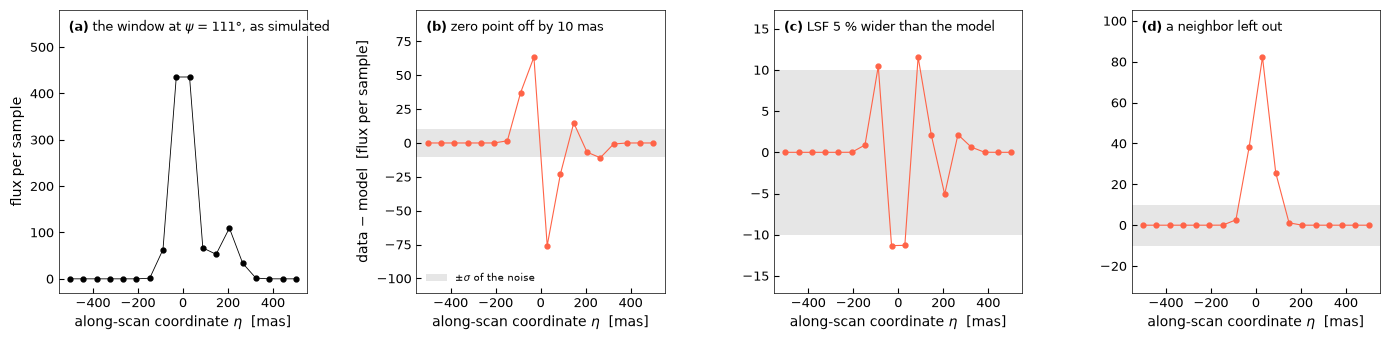

In [13]:
# Figure 1: (a) the window; (b to d) what each error leaves, data minus the true model, against the noise sigma
# (the band); each panel has its own scale
fig, axes = plt.subplots(1, 4, figsize=(14.0, 3.5))
axes[0].plot(grid, true_window, "o-", color="k", lw=0.6, ms=3.5)
axes[0].set(xlabel=r"along-scan coordinate $\eta$  [mas]", ylabel="flux per sample", ylim=(-30, 580))
letter(axes[0], "a", rf"the window at $\psi$ = {np.degrees(EVEN[j]):.0f}°, as simulated")
for ax, label, (name, window_in_error) in zip(axes[1:], "bcd", cases):
    ax.axhspan(-sigma_noise, sigma_noise, color="0.9", lw=0, label=r"$\pm\sigma$ of the noise")
    ax.plot(grid, window_in_error - true_window, "o-", color=ACCENT, lw=0.8, ms=3.5)
    ax.margins(y=0.25)                                       # room for the panel letter above the residual
    ax.set(xlabel=r"along-scan coordinate $\eta$  [mas]")
    letter(ax, label, name)
axes[1].set_ylabel("data $-$ model  [flux per sample]")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

## 2. The two images

*Paper: App. C.2, Eq. C.3 (the ramp filter of the inverse Radon transform; faststack). The effect of the noise on the two images is not in the paper; it is here because neither image carries an alarm.*

**What they assume.** The images take the zero points and nothing else:
no LSF, no σ, no source list. faststack assumes, through its trimmed first
estimate r₀, that the lowest samples at a pixel are the sky's level.

**What they return.** A zero-point error misplaces a window's strips, and
with 10 mas rms the images barely change. Noise alone does more. The ramp
filter of the inverse Radon transform multiplies the spectrum by |κ| and
amplifies the high frequencies, where the noise lives: at S/N 10 the sky is
mottled at a tenth of the companion's peak. faststack's samples in
Harrison's data are counts on a background, all positive; here the
background is zero, and with noise the lowest samples at a pixel are the
negative tail, so r₀ is negative. The weight exp(1 − (θ/r₀)²) depends on
(θ/r₀)² alone: samples with |θ| below |r₀| count more than one, samples
above it are suppressed, whatever their sign. At the companion, r₀ ≈ −40 at
a noise σ of 100, the samples that hold its light, around 100, are weighted
down and the pixel is pulled toward zero; near the primary, r₀ ≈ −200, the
primary's wing samples of 100 to 200 are no longer suppressed and the sky is
lifted above zero.

**The figure.** The two images in three cases, one row each: the zero points ignored, then noise σ 10 and
noise σ 100; the plus signs mark the primary and the companion.

**Do they warn.** No.

In [14]:
# where the images are read: the pixel of the companion (row companion_row for ddec, column companion_column for
# dra*), and the mask `empty`, a disc of 60 mas radius about (-200, -200) mas, away from both sources
axis = np.arange(-half, half + 1e-9, step)                    # the sky coordinate of the images' rows and columns [mas]
sky_x, sky_y = np.meshgrid(axis, axis)                        # dra* and ddec of every pixel [mas]
companion_row = np.argmin(np.abs(axis - theta[1]))            # the row nearest to the companion's ddec
companion_column = np.argmin(np.abs(axis - theta[0]))         # the column nearest to the companion's dra*
empty = np.hypot(sky_x + 200.0, sky_y + 200.0) < 60.0

In [15]:
# helper of this page: the windows of the pair at another noise level (sim.simulate_window)
def windows_of_noise(noise_sigma, seed_number=11):
    """The noisy windows of the page's pair on the 80 even directions, at a given noise level.

    Inputs
        noise_sigma   the noise sigma of one sample, in the windows' units
        seed_number   the seed of the noise's generator (why 11: not stated)
    Returns
        the windows, an array of J rows of N samples, flux per sample"""
    # one generator for all the windows, drawn in the order of the windows
    rng_noise = np.random.default_rng(seed_number)
    windows = []
    for eta_j in joint.scene_positions_al(theta, EVEN):
        windows.append(sim.simulate_window(eta_j, flux, inst, rng_noise, noise_sigma))
    return np.array(windows)

In [16]:
# the noise-free faststack, for reference; [0] keeps the image and omits the variance, the counts and the axis
clean = radon.faststack(EVEN, windows_of(theta, EVEN), inst, half, step)[0]
# np.nanmean: the mean without the pixels that hold no value (NaN: no sample fell on them)
print(f"noise-free faststack: {clean[companion_row, companion_column]:.0f} at the companion, "
      f"{np.nanmean(clean[empty]):.1f} on empty sky")

noise-free faststack: 105 at the companion, 0.0 on empty sky


In [17]:
# the three cases: the zero points ignored, the page's windows (sigma 10), and windows at sigma 100
# rows: a table of one row per case; a row holds the case's name and its windows
rows = (("zero points 10 mas rms, ignored, σ 10", wins_eta0),
        ("noise σ 10 (S/N 100)", wins),
        ("noise σ 100 (S/N 10)", windows_of_noise(100.0)))

zero points 10 mas rms, ignored, σ 10 : inverse Radon rms on empty sky 0.0005 flux/mas² (the companion's peak 0.0177); faststack 97 at the companion, 1.4 on empty sky
noise σ 10 (S/N 100)                  : inverse Radon rms on empty sky 0.0003 flux/mas² (the companion's peak 0.0177); faststack 103 at the companion, -1.0 on empty sky
noise σ 100 (S/N 10)                  : inverse Radon rms on empty sky 0.0022 flux/mas² (the companion's peak 0.0177); faststack 14 at the companion, 14.2 on empty sky


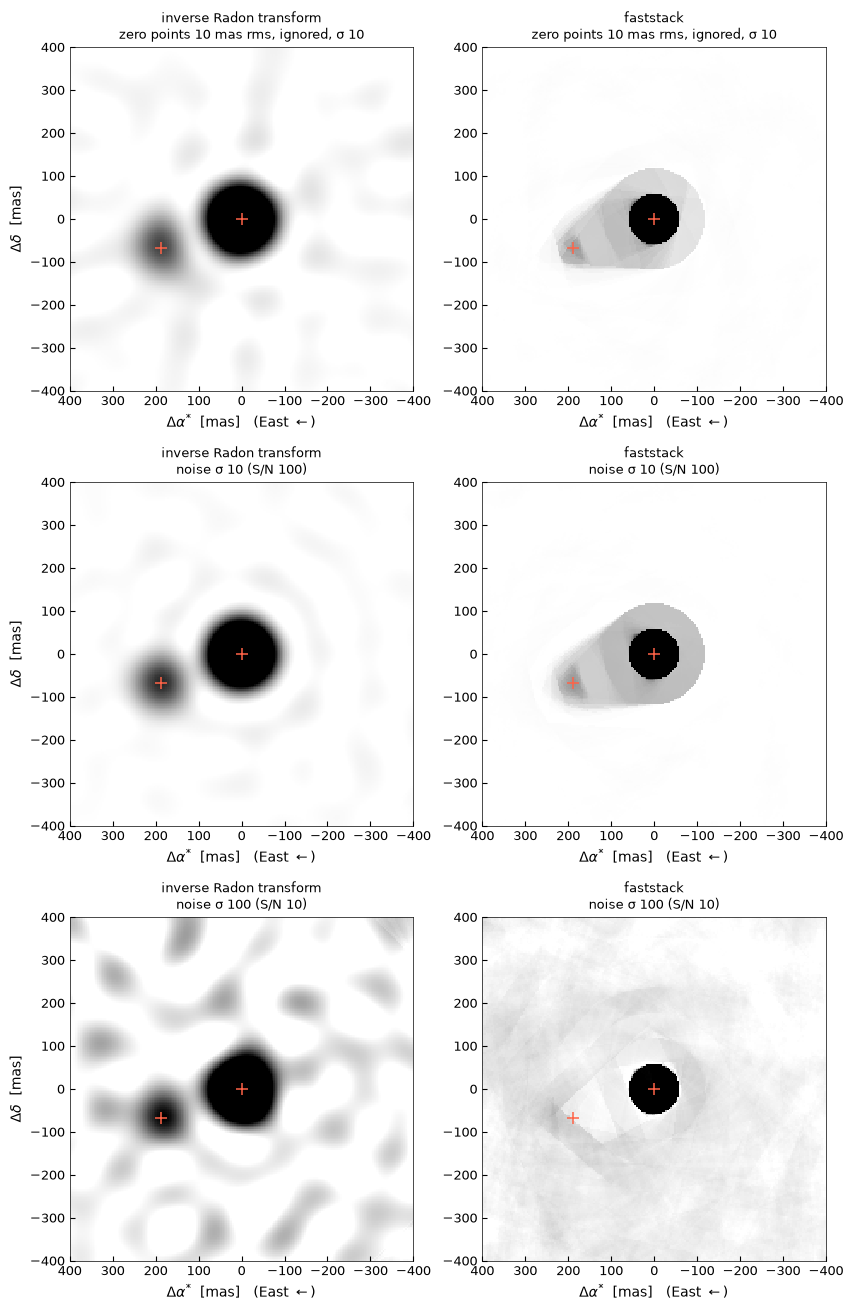

In [18]:
# Figure 2 and its table: the two images of each case, one row each, and their levels on the empty patch and at
# the companion. radon.filtered_backprojection returns (image, axis), radon.faststack (image, variance,
# number of samples, axis); `_` drops what is not used
fig, axes = plt.subplots(3, 2, figsize=(8.6, 13.2))
# the peak of the companion in a perfect inverse Radon image [flux/mas^2]: its flux over the area 2 pi sigma^2
# of the two-dimensional Gaussian of the LSF
companion_peak = flux[1] / (2 * np.pi * sigma_lsf ** 2)
for row, (name, case_windows) in zip(axes, rows):
    # the two images of the case. Every image is made with all zero points at 0: in the first case the windows
    # were cut with zero points of 10 mas rms, which the images ignore. The variance is not used below
    image, _ = radon.filtered_backprojection(EVEN, case_windows, inst, half, step)
    stack, variance, _, _ = radon.faststack(EVEN, case_windows, inst, half, step)
    print(f"{name:38s}: inverse Radon rms on empty sky {np.std(image[empty]):.4f} flux/mas² "
          f"(the companion's peak {companion_peak:.4f}); "
          f"faststack {stack[companion_row, companion_column]:.0f} at the companion, "
          f"{np.nanmean(stack[empty]):.1f} on empty sky")
    show(row[0], image, axis, f"inverse Radon transform\n{name}", vmax=0.02)
    show(row[1], stack, axis, f"faststack\n{name}", vmax=250)
    row[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## 3. The map of detections

*Paper: Sect. 3.3, Eq. 13 (the map). An error of the windows' zero points is not in the paper; it is here because the map takes each detection's η as a sky coordinate.*

**What it assumes.** That each detection's η is in sky coordinates, the
window's zero point already added back, with an honest error bar.

**What it returns.** A zero-point error that is not added back shifts each
line by that error: with 10 mas rms the lines scatter about the crossing,
the peak broadens and moves by a few mas. A wrong LSF width or a missing
neighbor enters the map only through the per-window fits that produce the
detections (`reduce_campaign`); this page uses the tutorials' stand-in
detections, so it does not show that path. A wrong σ enters through their
error bars, which set the ridges' widths. Here only the zero points are
shown.

**The figure.** The map within 60 mas of the companion, with the zero points added back and with them
ignored; the plus sign is the companion's true position, the open circle the map's peak.

**Does it warn.** `bp.peak_consistency` counts the lines that miss the peak;
with 10 mas errors on 5 to 10 mas error bars most still pass.

In [19]:
# the detections, and for each one the index of its window (window_of_detection), found by its scan angle
# the teaching detections (the stand-in, not a reduction of windows)
d_psi, d_eta, d_sigma = detections(theta, EVEN)
window_of_detection = []
for psi_detection in d_psi:
    # the window whose scan angle is nearest to the detection's
    window_of_detection.append(int(np.argmin(np.abs(EVEN - psi_detection))))
window_of_detection = np.array(window_of_detection)

zero points added back              : peak (187, -69), 1.1 mas from the truth, width 6.8 mas; 76 of 76 lines through it
zero points of 10 mas rms ignored   : peak (195, -66), 7.5 mas from the truth, width 8.7 mas; 62 of 76 lines through it


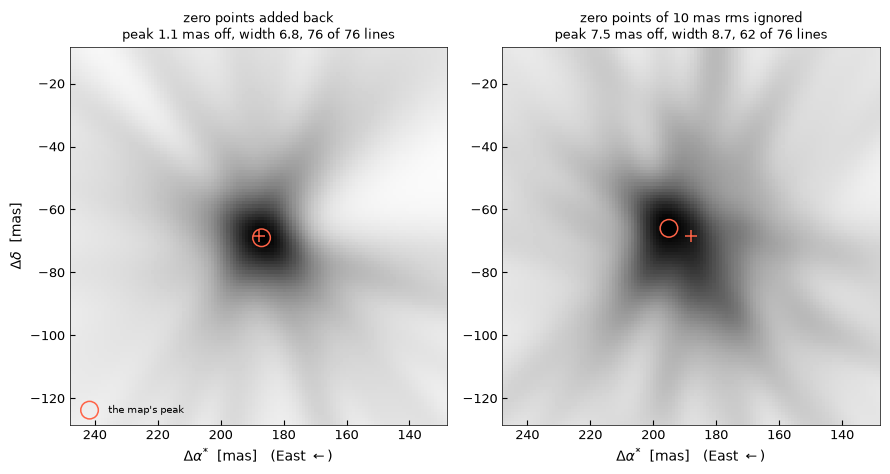

In [20]:
# Figure 3: the map near the companion with the zero points added back, and with them ignored (each line
# shifted by its window's zero point, eta0_true[window_of_detection]). bp.peak_consistency returns (keep,
# distance); keep is the mask of the lines that pass through the peak
fig, axes = plt.subplots(1, 2, figsize=(9.0, 4.7))
# the detections' along-scan positions in the two cases: on the sky, and in the frame of each window (the
# window's zero point subtracted, and not added back)
eta_ignored = d_eta - eta0_true[window_of_detection]
MAP_CASES = (("zero points added back", d_eta), ("zero points of 10 mas rms ignored", eta_ignored))
for ax, (name, eta) in zip(axes, MAP_CASES):
    # the map of the detections: its peak, its width, the map and the map's axis; then the lines through the peak
    peak, width, sky_map, map_axis = bp.map_peak(d_psi, eta, d_sigma, 300.0, 1.0)
    keep, _ = bp.peak_consistency(d_psi, eta, d_sigma, peak, width)
    # truth: the distance of the map's peak from the companion's true position [mas]
    peak_error = np.array(peak) - theta
    peak_distance = np.hypot(peak_error[0], peak_error[1])
    print(f"{name:36s}: peak ({peak[0]:.0f}, {peak[1]:.0f}), {peak_distance:.1f} mas from the truth, "
          f"width {width:.1f} mas; {keep.sum()} of {d_psi.size} lines through it")
    title = f"{name}\npeak {peak_distance:.1f} mas off, width {width:.1f}, {keep.sum()} of {d_psi.size} lines"
    show(ax, sky_map, map_axis, title)
    large_circle = dict(SEED, s=160)                          # the SEED marker, larger
    ax.scatter(*peak, **large_circle, label="the map's peak")
    ax.set(xlim=(theta[0] + 60, theta[0] - 60), ylim=(theta[1] - 60, theta[1] + 60))   # 60 mas about the companion
axes[0].set_ylabel(NORTH)
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

## 4. The joint fit

*Paper: Sect. 4.3, Eq. 18 (the joint likelihood); Sect. 6.2 (errors in the LSF).*

**What it assumes.** All four inputs as given.

**What it returns.** Zero points of 10 mas rms ignored: a bias of about one
error bar, because the errors are random over the directions, while the
primary's profile is misplaced in every window. The LSF width 5 % off: the
wings are unexplained, the fit explains them with what it has, the
primary's flux rises and the companion moves by several error bars; 10 %
off, by more. The noise σ told as half or double: the estimate does not
move at all, because one σ for every sample does not change the least
squares minimizer, but the error bars scale with σ. A neighbor left out:
its light is explained with the pair's in the windows where it falls near
them, a bias of up to four error bars.

**Does it warn.** Yes, for every input here; read χ²/dof against its own
scatter. For a correct model it lies about 1 with a 1-σ scatter of
√(2/dof) = 0.037 at these 1436 degrees of freedom. The zero points give
7.5, the noise σ 4 or 0.25, the neighbor 3 to 34, all far outside it. The
LSF width gives 1.17 at +5 % and 1.20 at −5 %, 4.6 and 5.4 of that
scatter (a correct model reaches 1.17 or more with a chance of about
7 × 10⁻⁶), and 1.7 at 10 %. So χ² does notice a 5 % width error at this
S/N. What it cannot do is name it: a noise σ told 7.5 % too small also
gives 1.17 (χ²/dof scales as 1/s² when σ is told as s σ), and that error
moves no estimate, while the width error moves the companion by up to
3.7 error bars. The remedy is a model of the LSF fitted on isolated
stars, or a width fitted with the scene; neither is in this package.

In [21]:
# the same windows fitted with the model as simulated, then with the zero points in error: ignored, and given
# to the fit (eta0=)
fit_as_simulated = joint.fit_joint(wins, EVEN, seed, inst, sigma_noise)
report("the model as simulated", fit_as_simulated, theta, DOF)
fit_ignored = joint.fit_joint(wins_eta0, EVEN, seed, inst, sigma_noise)
report("zero points 10 mas rms, ignored", fit_ignored, theta, DOF)
fit_modeled = joint.fit_joint(wins_eta0, EVEN, seed, inst, sigma_noise, eta0=eta0_true)
report("zero points 10 mas rms, modeled", fit_modeled, theta, DOF)

the model as simulated                   fit − truth (  1.11,   0.41)   pulls (  1.4,   0.5)   fluxes 1000, 200   chi2/dof 1.01
zero points 10 mas rms, ignored          fit − truth ( -0.86,   1.28)   pulls ( -1.1,   1.6)   fluxes 989, 196   chi2/dof 7.50
zero points 10 mas rms, modeled          fit − truth ( -0.67,   0.27)   pulls ( -0.9,   0.4)   fluxes 1000, 199   chi2/dof 1.00


In [22]:
# the model's LSF 5 % narrower, 5 % wider and 10 % wider than the LSF that made the windows
for factor in (0.95, 1.05, 1.10):
    # the instrument of the model: the page's sampling, with the LSF's width times `factor`
    inst_model = ins.Instrument.gaussian(fwhm_mas=FWHM * factor, pitch_mas=59.0, n_samples=18)
    fit_width = joint.fit_joint(wins, EVEN, seed, inst_model, sigma_noise)
    report(f"model LSF width × {factor:.2f}", fit_width, theta, DOF)

model LSF width × 0.95                   fit − truth ( -0.73,   1.10)   pulls ( -1.0,   1.6)   fluxes 977, 201   chi2/dof 1.20
model LSF width × 1.05                   fit − truth (  3.08,  -0.31)   pulls (  3.7,  -0.4)   fluxes 1023, 197   chi2/dof 1.17
model LSF width × 1.10                   fit − truth (  5.14,  -1.07)   pulls (  5.6,  -1.2)   fluxes 1046, 194   chi2/dof 1.70


In [23]:
# the noise sigma told as half and as double its value
for factor in (0.5, 2.0):
    # the windows have noise of sigma_noise; the fit is told sigma_noise times `factor`
    fit_sigma = joint.fit_joint(wins, EVEN, seed, inst, sigma_noise * factor)
    report(f"noise σ told as × {factor:.1f}", fit_sigma, theta, DOF)

noise σ told as × 0.5                    fit − truth (  1.11,   0.41)   pulls (  2.9,   1.1)   fluxes 1000, 200   chi2/dof 4.04
noise σ told as × 2.0                    fit − truth (  1.11,   0.41)   pulls (  0.7,   0.3)   fluxes 1000, 200   chi2/dof 0.25


In [24]:
# a third star in the windows: left out of the model, then modeled. The fit with the neighbor has four
# position parameters; [:2] keeps the companion's two for the report
for neighbor_position, neighbor_flux in neighbors:
    # step 1, the noisy windows of the three sources. Every neighbor gets a new generator of seed 10, so the
    # three sets of windows have the same noise
    theta_three = np.r_[theta, neighbor_position]             # the companion's (dra*, ddec), then the neighbor's
    flux_three = np.r_[flux, neighbor_flux]
    rng_noise = np.random.default_rng(10)
    wins_three = windows_of(theta_three, EVEN, flux=flux_three, rng=rng_noise)

    # step 2, the fit of two sources: the neighbor is in the windows and not in the model
    fit_two = joint.fit_joint(wins_three, EVEN, seed, inst, sigma_noise)
    report(f"neighbor at {neighbor_position}, flux {neighbor_flux:.0f}, ignored", fit_two, theta, DOF)

    # step 3, the fit of three sources, the neighbor started (5, 5) mas from its true position. For the report
    # the fit's table is copied with the companion's two parameters only; the degrees of freedom are 80 x 18
    # samples minus four coordinates and three fluxes
    seed_three = np.r_[seed, np.array(neighbor_position) + [5.0, 5.0]]
    fit_three = joint.fit_joint(wins_three, EVEN, seed_three, inst, sigma_noise)
    fit_companion = dict(fit_three, theta=fit_three["theta"][:2], sigma_theta=fit_three["sigma_theta"][:2])
    report(f"{'':>34s} modeled", fit_companion, theta, EVEN.size * grid.size - 7)

neighbor at (-200.0, 230.0), flux 400, ignored fit − truth (  0.50,   1.63)   pulls (  0.7,   2.4)   fluxes 1060, 221   chi2/dof 34.37
                                   modeled fit − truth ( -0.06,   0.65)   pulls ( -0.1,   0.8)   fluxes 1001, 197   chi2/dof 1.03
neighbor at (120.0, 250.0), flux 150, ignored fit − truth (  0.18,   2.85)   pulls (  0.2,   4.0)   fluxes 1023, 214   chi2/dof 5.61
                                   modeled fit − truth ( -0.07,   0.66)   pulls ( -0.1,   0.9)   fluxes 1001, 197   chi2/dof 1.03
neighbor at (-150.0, -150.0), flux 100, ignored fit − truth ( -0.53,   0.14)   pulls ( -0.7,   0.2)   fluxes 1023, 205   chi2/dof 3.00
                                   modeled fit − truth ( -0.08,   0.63)   pulls ( -0.1,   0.8)   fluxes 1001, 197   chi2/dof 1.03


*Paper: Sect. 6.3 (the campaigns there are fitted with a free primary).*

**A fifth input: the reference position.** The windows are cut about a
reference position, the primary's predicted position, and every sky offset
is measured from it. By default the fit pins the primary there
(`free_primary=False`): θ holds the companion only, and an error of the
reference position is an input in error like the four above.
`free_primary=True` gives the primary its own offset from the reference
position (in a moving scene, also its own residual proper motion and
parallax difference) as one more block in front of the companion's, so θ
holds (Δα\*₀, Δδ₀, Δα\*₁, Δδ₁). Every offset stays measured from the
reference position: the companion's offset from the primary is its block
minus the primary's. The two images and the map do not place the primary,
so they show it where it is.

**What it returns.** The same pair, the windows cut about a reference
position that misses the primary by 0 to 10 mas along (3, −2). Pinned, the
fit moves the companion to absorb the primary's offset: 1.8 error bars at
3.6 mas, 3.2 at 5 mas, 8.8 at 10 mas, the companion's flux rising as the
primary's falls. Free, the fit returns the primary's offset to its 1-σ of
0.15 mas and the companion with pulls of 1.4 to 1.5 and 0.5 at every offset,
those of the pinned fit on windows centred on the primary (1.4, 0.5). The price of the freedom is small here:
two more parameters, and the companion's error bar grows by at most 1 %.

**Does it warn.** χ²/dof hears it: 1.05 at 1 mas, 1.46 at 3.6, 1.86 at 5 and
4.27 at 10, against 1.01 for the free fit, where the 1-σ scatter of χ²/dof
with 1436 degrees of freedom is 0.04. The remedy is `free_primary=True`.

In [25]:
# the windows centred on a reference position that misses the primary, along (3, -2) mas, at five offsets; each
# set fitted with the primary pinned and free. np.r_[offset, theta + offset] puts the primary's block before
# the companion's; sigma_pinned and sigma_free keep the two fits' error bars of the case with no offset
OFFSET_3_2 = np.hypot(3.0, -2.0)                              # the length of the offset (3, -2) [mas]
direction = np.array([3.0, -2.0]) / OFFSET_3_2                # the unit vector (dra*, ddec) of every offset
for size in (0.0, 1.0, OFFSET_3_2, 5.0, 10.0):
    # step 1, the scene: both sources are `offset` from the reference position
    offset = size * direction                                 # the primary's offset from the reference position [mas]
    # the primary's block first; every offset is from the reference position
    theta_free = np.r_[offset, theta + offset]

    # step 2, the noisy windows. Every offset gets a new generator of seed 8, the seed of the page's windows:
    # the five sets have the same noise. free_primary=True reads the primary's position from theta_free
    rng_noise = np.random.default_rng(8)                      # the noise of the page's windows
    wins_offset = []
    for eta_j in joint.scene_positions_al(theta_free, EVEN, free_primary=True):
        wins_offset.append(sim.simulate_window(eta_j, flux, inst, rng_noise, sigma_noise))
    wins_offset = np.array(wins_offset)

    # step 3, the two fits of those windows: the primary pinned at the reference position (the companion's two
    # coordinates are fitted), and the primary free (np.r_ puts its start, (0, 0), before the companion's)
    seed_offset = theta + offset + [8.0, -6.0]                # the page's seed, about the companion's sky offset
    pinned = joint.fit_joint(wins_offset, EVEN, seed_offset, inst, sigma_noise)
    seed_free = np.r_[0.0, 0.0, seed_offset]
    free = joint.fit_joint(wins_offset, EVEN, seed_free, inst, sigma_noise, free_primary=True)
    report(f"primary {size:4.1f} mas off, pinned", pinned, theta + offset, DOF)
    report(f"{'':>20s} free", free, theta_free, DOF - 2)      # two more parameters: the primary's coordinates
    if size == 0.0:
        # where the pinned model is right: the error bars of the two fits
        sigma_pinned = pinned["sigma_theta"]
        sigma_free = free["sigma_theta"]

primary  0.0 mas off, pinned             fit − truth (  1.11,   0.41)   pulls (  1.4,   0.5)   fluxes 1000, 200   chi2/dof 1.01
                     free                fit − truth (  0.12,  -0.06,   1.20,   0.38)   pulls (  0.8,  -0.4,   1.5,   0.5)   fluxes 1000, 199   chi2/dof 1.01
primary  1.0 mas off, pinned             fit − truth (  0.45,   0.58)   pulls (  0.6,   0.8)   fluxes 999, 201   chi2/dof 1.05
                     free                fit − truth (  0.12,  -0.06,   1.19,   0.38)   pulls (  0.8,  -0.4,   1.5,   0.5)   fluxes 1000, 199   chi2/dof 1.01
primary  3.6 mas off, pinned             fit − truth ( -1.35,   1.05)   pulls ( -1.8,   1.4)   fluxes 997, 205   chi2/dof 1.46
                     free                fit − truth (  0.11,  -0.06,   1.18,   0.39)   pulls (  0.8,  -0.4,   1.5,   0.5)   fluxes 1000, 199   chi2/dof 1.01
primary  5.0 mas off, pinned             fit − truth ( -2.35,   1.32)   pulls ( -3.2,   1.8)   fluxes 995, 208   chi2/dof 1.86
                 

In [26]:
# the price of the free primary: the error bars of the two fits. In the free fit, [:2] is the primary's block
# and [2:] the companion's
print(f"\nthe 1-sigma with the primary on the reference position [mas]: companion {sigma_pinned.round(3)} pinned, "
      f"{sigma_free[2:].round(3)} free; the primary {sigma_free[:2].round(3)} free")


the 1-sigma with the primary on the reference position [mas]: companion [0.769 0.761] pinned, [0.776 0.763] free; the primary [0.146 0.144] free


## Summary

| atom | effect in this case | alarm | remedy |
|---|---|---|---|
| inverse Radon transform | zero-point errors of 10 mas: negligible; noise amplified by the ramp, a mottled sky at S/N 10 | none | a lower-pass filter would trade resolution for noise; not in this package |
| faststack | zero-point errors: negligible; noise makes r₀ negative, pulls the sources toward zero and lifts the sky near the primary | none | a background level or a floor on r₀ (a decision for the shared package) |
| map of detections | zero points not added back shift every line by their error; the peak broadens and moves by a few mas | `bp.peak_consistency` counts the lines that miss | add the zero points back before pooling |
| joint fit | zero points: one error bar; LSF width 5 %: several error bars; noise σ: error bars scaled, estimate unchanged; a missing neighbor: up to four error bars; the reference position 3.6 mas off the primary, pinned: 1.8 error bars, 10 mas off: 8.8 | χ²/dof hears all, against its scatter 0.037; the LSF width at 5 % only as 1.17 to 1.20 (4.6 to 5.4σ), which a noise σ told 7.5 % too small also gives | the inputs from the data's own calibration; the LSF from isolated stars to a few percent; the scene complete; `free_primary=True` for the reference position |

## What this establishes

- χ² against its degrees of freedom, read with its scatter √(2/dof), is the
  one alarm the fit carries, and it hears every input in error here. It does
  not say which one: a 5 % LSF width error raises χ²/dof to 1.17, 4.6σ at
  1436 degrees of freedom, as a noise σ 7.5 % too small would, but it also
  moves the companion by several error bars. The profile must be known, from
  isolated stars, to better than a few percent.
- A pinned primary takes the reference position as exact. An error of a few
  mas moves the companion by error bars and raises χ²; `free_primary=True`
  fits the primary's offset for two parameters and, in this case, about 1 %
  of the companion's precision.
- The noise σ does not move the estimate; it sets the error bars and the
  alarm, and must come from the data's error model.
- The pictures have no alarm. The ramp filter amplifies noise; faststack's
  trimmed estimator assumes positive samples on a background, and with a
  zero background and noise its r₀ turns negative, the sources are pulled
  toward zero and the sky near the primary is lifted.